# Netflix Customer Intelligence & AI Analytics Copilot
## Advanced Exploratory Data Analysis (EDA)

**Purpose:** Explore customer demographics, subscriptions, revenue, churn, viewing behaviour, content performance, customer support and feedback.

**Data source:** `data/processed/`  
**Scope:** Nine processed datasets, business-focused visualizations, data-quality checks and actionable findings.

> Important: Churn labels and historical subscription records are treated separately. Customer-level and transaction-level metrics are not interchangeable. Correlation does not establish causation.


## 1. Import libraries and configure analysis

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

DATA = Path("../data/processed")
REPORTS = Path("../data/reports/eda")
REPORTS.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 50)

print("EDA environment initialized.")
print("Data directory:", DATA.resolve())


EDA environment initialized.
Data directory: /workspaces/Netflix-Customer-Intelligence/data/processed


## 2. Load all nine processed datasets

In [2]:
files = {
    "customers": "customers.csv",
    "subscriptions": "subscriptions.csv",
    "plans": "subscription_plans.csv",
    "payments": "payments.csv",
    "churn": "churn_labels.csv",
    "viewing": "viewing_activity.csv",
    "content": "content.csv",
    "tickets": "support_tickets.csv",
    "feedback": "customer_feedback.csv",
}

data = {}
for name, filename in files.items():
    path = DATA / filename
    if not path.exists():
        raise FileNotFoundError(f"Missing processed dataset: {path}")
    data[name] = pd.read_csv(path)
    print(f"{name:15} {data[name].shape}")

customers = data["customers"].copy()
subscriptions = data["subscriptions"].copy()
plans = data["plans"].copy()
payments = data["payments"].copy()
churn = data["churn"].copy()
viewing = data["viewing"].copy()
content = data["content"].copy()
tickets = data["tickets"].copy()
feedback = data["feedback"].copy()

date_columns = {
    "customers": ["registration_date"],
    "subscriptions": ["subscription_start_date", "subscription_end_date", "cancellation_date"],
    "payments": ["payment_date"],
    "churn": ["churn_date"],
    "viewing": ["viewing_date"],
    "tickets": ["ticket_date"],
    "feedback": ["feedback_date"],
}

for name, columns in date_columns.items():
    for column in columns:
        if column in data[name].columns:
            data[name][column] = pd.to_datetime(data[name][column], errors="coerce")

customers = data["customers"]
subscriptions = data["subscriptions"]
payments = data["payments"]
churn = data["churn"]
viewing = data["viewing"]
tickets = data["tickets"]
feedback = data["feedback"]


customers       (8000, 12)
subscriptions   (8875, 10)
plans           (3, 6)


payments        (110735, 8)
churn           (8000, 4)
viewing         (66422, 9)
content         (500, 9)
tickets         (6120, 11)


feedback        (5046, 6)


## 3. Data quality and dataset overview

In [3]:
quality = []
for name, df in data.items():
    quality.append({
        "dataset": name,
        "rows": len(df),
        "columns": len(df.columns),
        "duplicate_rows": int(df.duplicated().sum()),
        "missing_cells": int(df.isna().sum().sum()),
        "missing_pct": round(df.isna().sum().sum() / max(df.size, 1) * 100, 2)
    })

quality_df = pd.DataFrame(quality)
display(quality_df)
quality_df.to_csv(REPORTS / "eda_data_quality_summary.csv", index=False)

for name, df in data.items():
    print(f"\n{name.upper()} — columns")
    print(list(df.columns))


,dataset,rows,columns,duplicate_rows,missing_cells,missing_pct
0,customers,8000,12,0,9472,9.87
1,subscriptions,8875,10,0,21768,24.53
2,plans,3,6,0,0,0.00
3,payments,110735,8,0,214264,24.19
4,churn,8000,4,0,12018,37.56
5,viewing,66422,9,0,1195,0.20
6,content,500,9,0,0,0.00
7,tickets,6120,11,0,3117,4.63
8,feedback,5046,6,0,0,0.00



CUSTOMERS — columns
['customer_id', 'first_name', 'last_name', 'age', 'gender', 'country', 'state_or_region', 'city', 'registration_date', 'acquisition_channel', 'customer_segment', 'preferred_language']

SUBSCRIPTIONS — columns
['subscription_id', 'customer_id', 'plan_id', 'subscription_start_date', 'subscription_end_date', 'subscription_status', 'auto_renew', 'cancellation_date', 'cancellation_reason', 'monthly_price']

PLANS — columns
['plan_id', 'plan_name', 'monthly_price', 'video_quality', 'max_devices', 'advertisements']

PAYMENTS — columns
['payment_id', 'customer_id', 'subscription_id', 'payment_date', 'amount', 'payment_method', 'payment_status', 'failed_payment_reason']

CHURN — columns
['customer_id', 'churned', 'churn_date', 'churn_reason']

VIEWING — columns
['viewing_id', 'customer_id', 'content_id', 'viewing_date', 'watch_duration_minutes', 'completion_percentage', 'device_type', 'login_location', 'session_duration_minutes']

CONTENT — columns
['content_id', 'title', '

## 4. Prepare analysis datasets

In [4]:
# Customer-level churn view: one row per customer where available.
customer_churn = customers.merge(churn, on="customer_id", how="left", validate="one_to_one")

# Successful payments only for revenue analysis.
successful_payments = payments.copy()
if "payment_status" in successful_payments.columns:
    successful_payments = successful_payments[
        successful_payments["payment_status"].astype(str).str.strip().str.lower().isin(["success", "successful"])
    ].copy()

if "payment_date" in successful_payments.columns:
    successful_payments["payment_month"] = successful_payments["payment_date"].dt.to_period("M").astype(str)

# Viewing enriched with content attributes.
viewing_content = viewing.merge(content, on="content_id", how="left", validate="many_to_one")

# Customer support and feedback enriched with customer attributes.
tickets_customer = tickets.merge(
    customers[["customer_id", "country", "customer_segment"]],
    on="customer_id", how="left", validate="many_to_one"
)
feedback_customer = feedback.merge(
    customers[["customer_id", "country", "customer_segment"]],
    on="customer_id", how="left", validate="many_to_one"
)

print("Customer rows:", len(customers))
print("Customer churn rows:", len(customer_churn))
print("Successful payment rows:", len(successful_payments))
print("Viewing rows:", len(viewing_content))


Customer rows: 8000
Customer churn rows: 8000
Successful payment rows: 103529
Viewing rows: 66422


## 5. Customer demographics

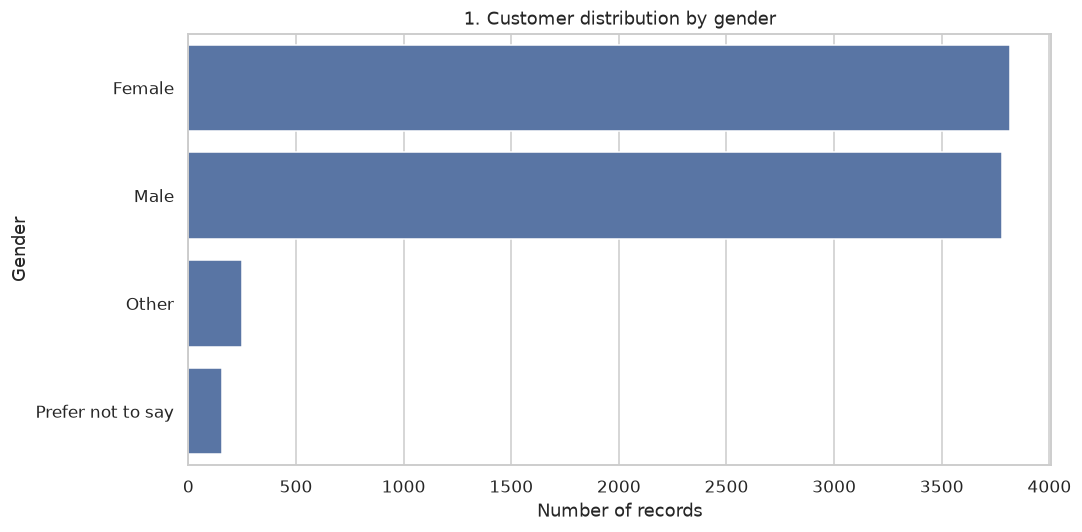

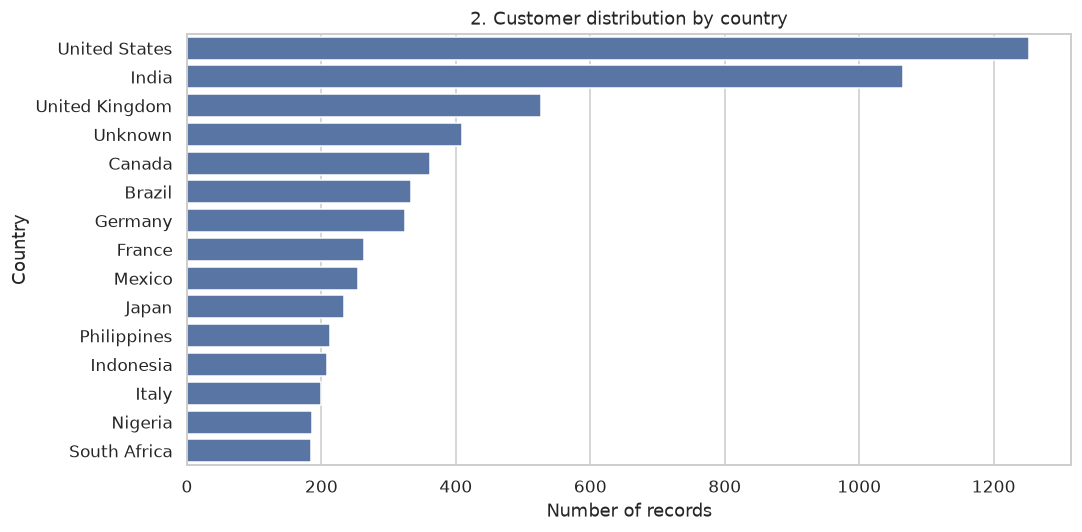

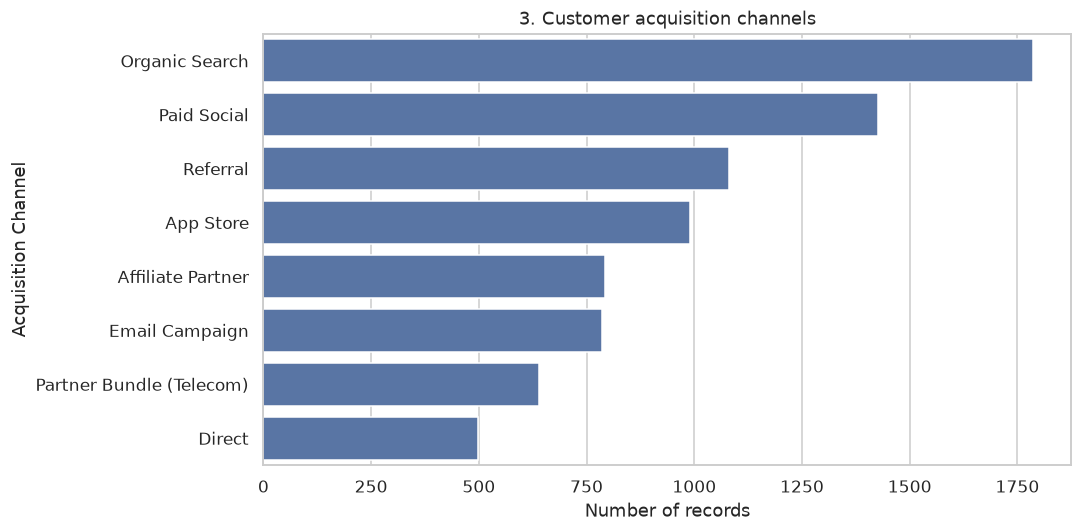

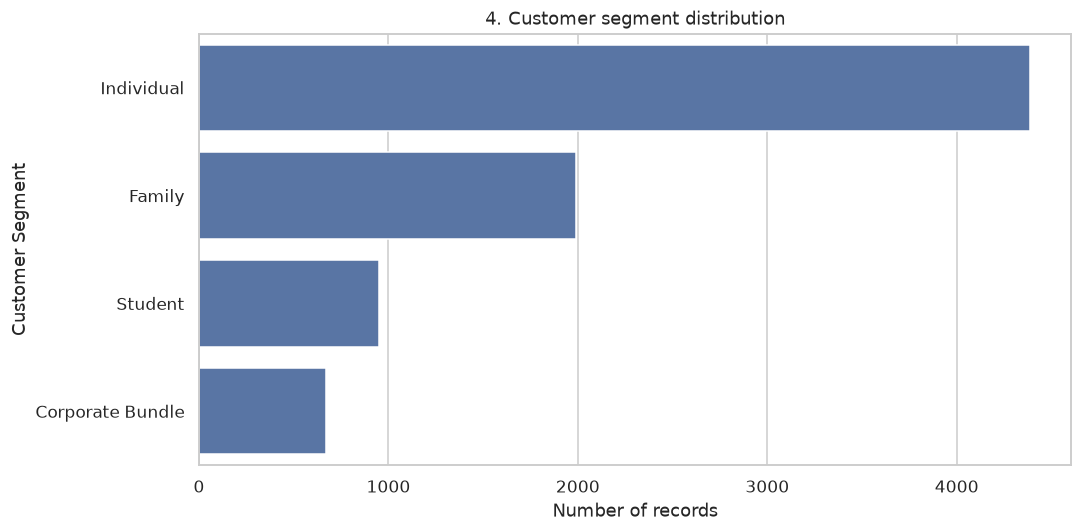

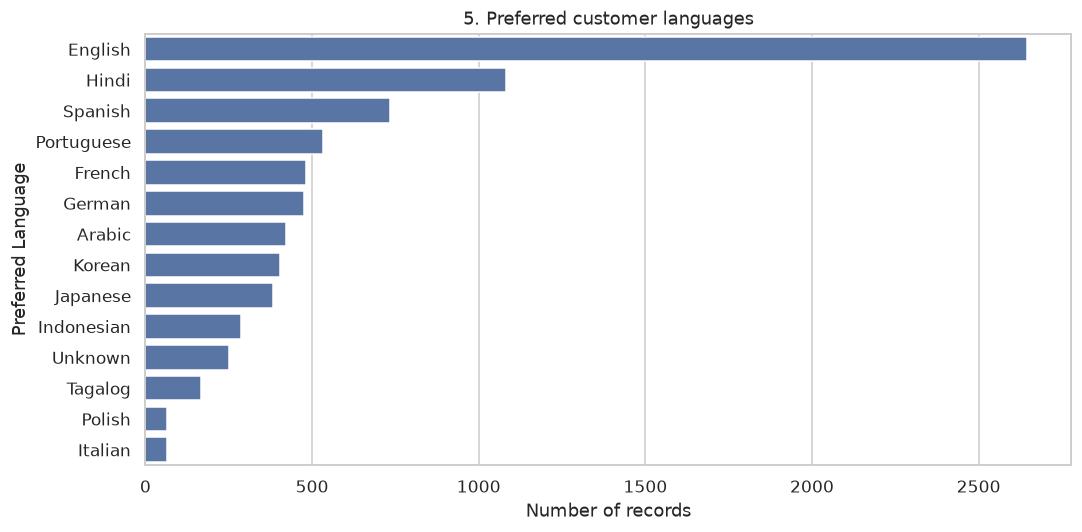

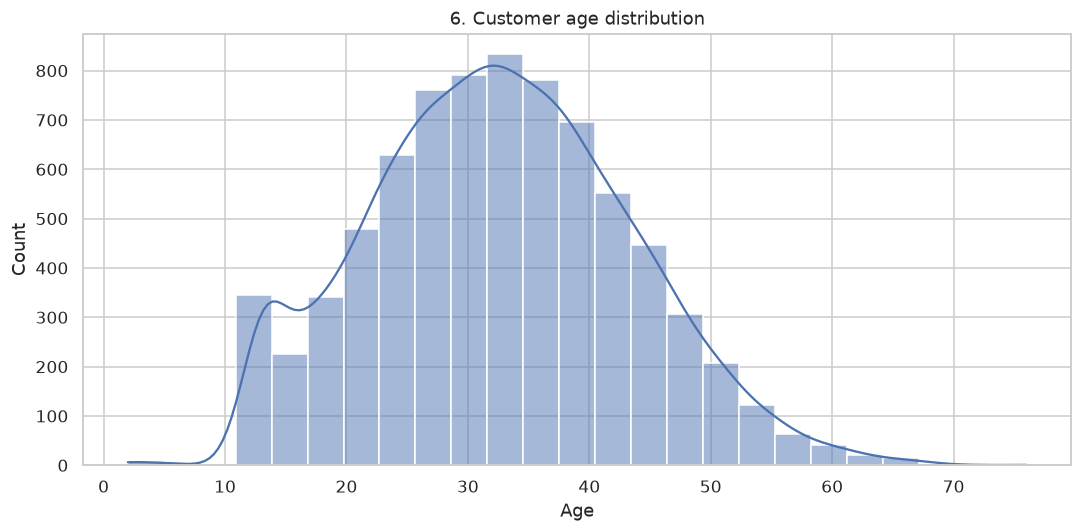

In [5]:
def count_plot(df, column, title, top=15):
    if column not in df.columns:
        print(f"Skipped: {column} not available")
        return
    values = df[column].fillna("Unknown").astype(str).value_counts().head(top)
    if values.empty:
        print(f"Skipped: no values for {column}")
        return
    plt.figure()
    sns.barplot(x=values.values, y=values.index)
    plt.title(title)
    plt.xlabel("Number of records")
    plt.ylabel(column.replace("_", " ").title())
    plt.tight_layout()
    plt.show()

def hist_plot(df, column, title, bins=25):
    if column not in df.columns:
        print(f"Skipped: {column} not available")
        return
    values = pd.to_numeric(df[column], errors="coerce").dropna()
    if values.empty:
        print(f"Skipped: no numeric values for {column}")
        return
    plt.figure()
    sns.histplot(values, bins=bins, kde=True)
    plt.title(title)
    plt.xlabel(column.replace("_", " ").title())
    plt.tight_layout()
    plt.show()

count_plot(customers, "gender", "1. Customer distribution by gender")
count_plot(customers, "country", "2. Customer distribution by country")
count_plot(customers, "acquisition_channel", "3. Customer acquisition channels")
count_plot(customers, "customer_segment", "4. Customer segment distribution")
count_plot(customers, "preferred_language", "5. Preferred customer languages")
hist_plot(customers, "age", "6. Customer age distribution")


## 6. Subscription and plan analysis

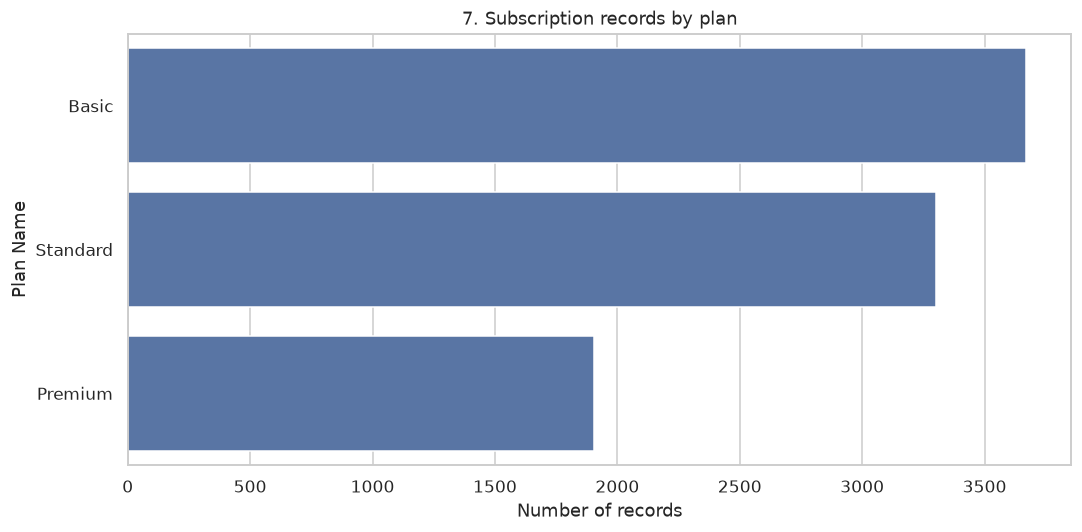

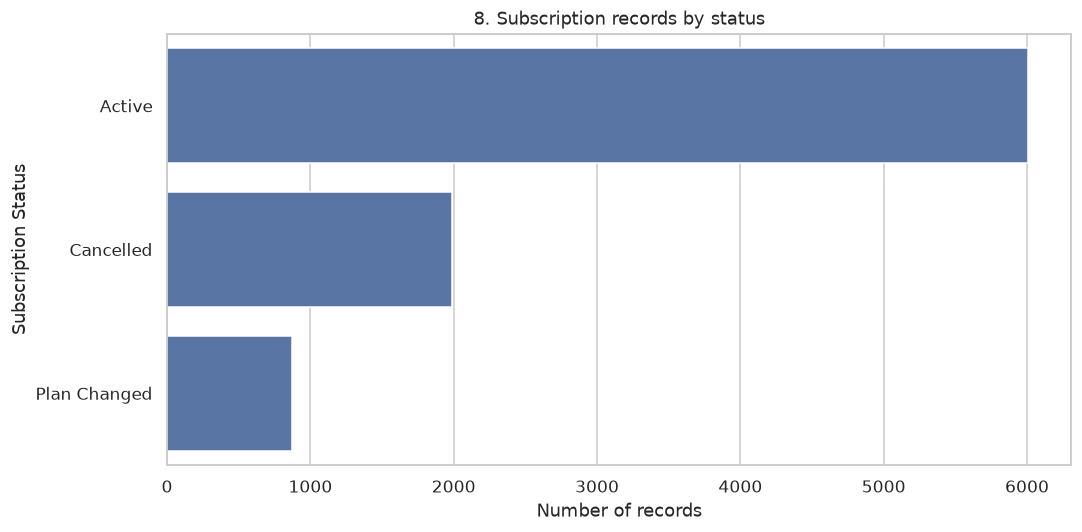

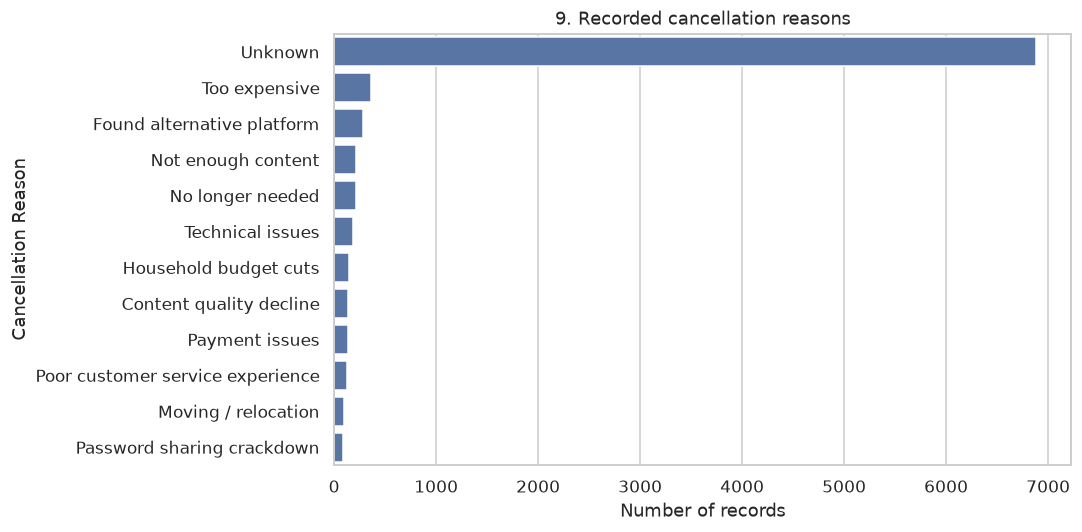

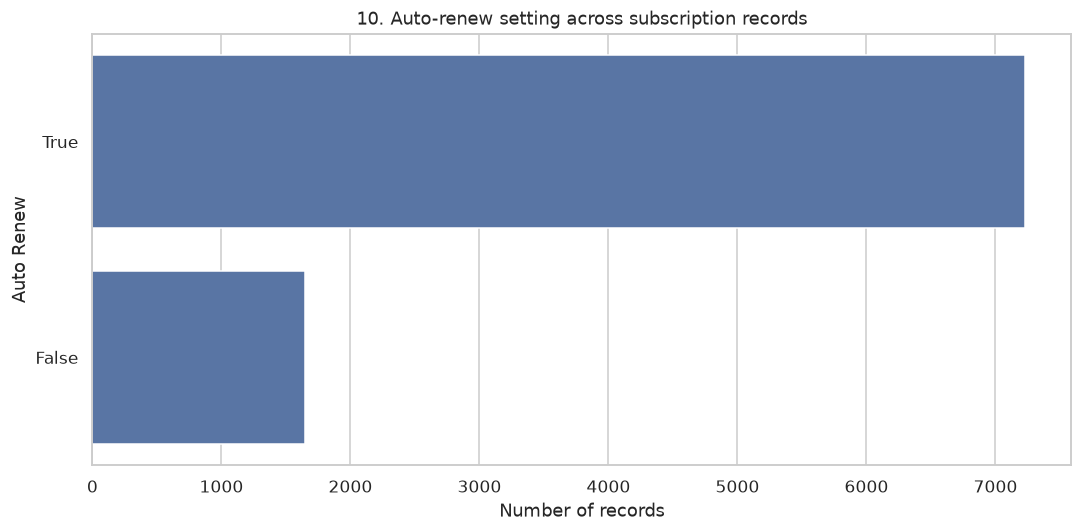

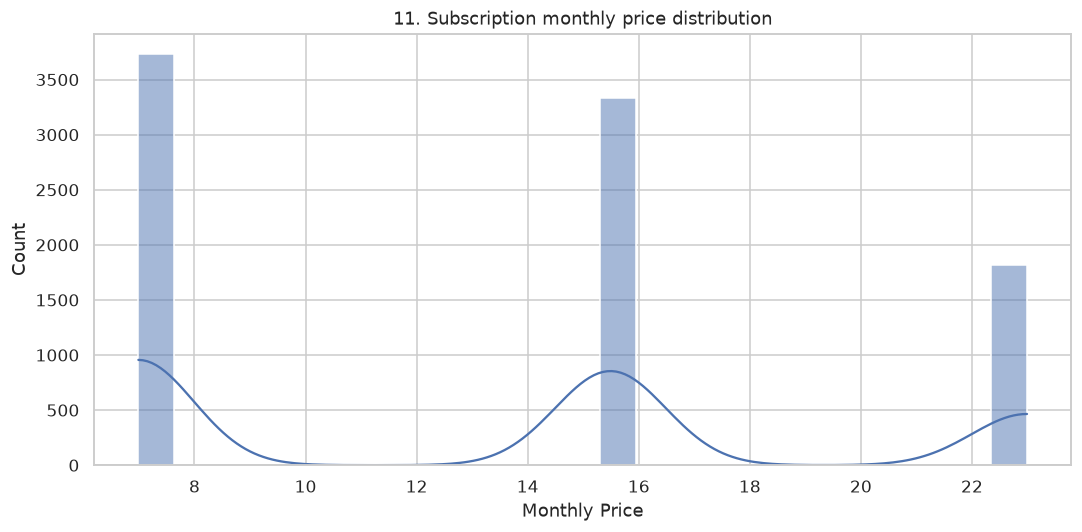

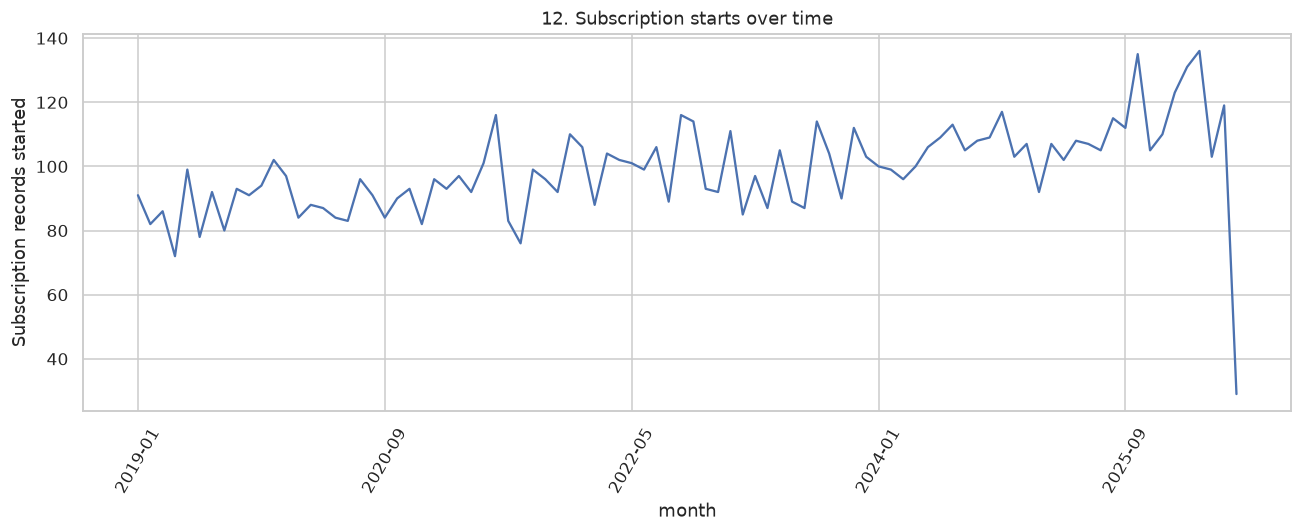

In [6]:
# Subscription plan mix (historical subscription records, not unique current customers).
subscription_plans = subscriptions.merge(
    plans[["plan_id", "plan_name"]],
    on="plan_id", how="left", validate="many_to_one"
)
count_plot(subscription_plans, "plan_name", "7. Subscription records by plan")
count_plot(subscriptions, "subscription_status", "8. Subscription records by status")
count_plot(subscriptions, "cancellation_reason", "9. Recorded cancellation reasons")
count_plot(subscriptions, "auto_renew", "10. Auto-renew setting across subscription records")

if "monthly_price" in subscriptions.columns:
    hist_plot(subscriptions, "monthly_price", "11. Subscription monthly price distribution")

if "subscription_start_date" in subscriptions.columns:
    monthly_starts = subscriptions.dropna(subset=["subscription_start_date"]).copy()
    monthly_starts["month"] = monthly_starts["subscription_start_date"].dt.to_period("M").astype(str)
    trend = monthly_starts.groupby("month").size()
    plt.figure(figsize=(12, 5))
    trend.plot()
    plt.title("12. Subscription starts over time")
    plt.ylabel("Subscription records started")
    plt.xticks(rotation=60)
    plt.tight_layout()
    plt.show()


## 7. Revenue and payment analysis

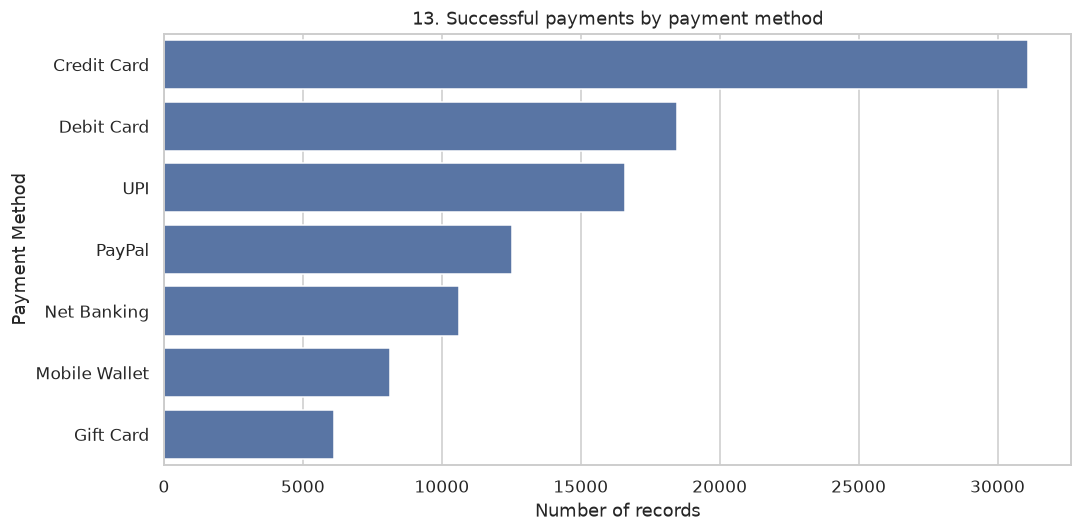

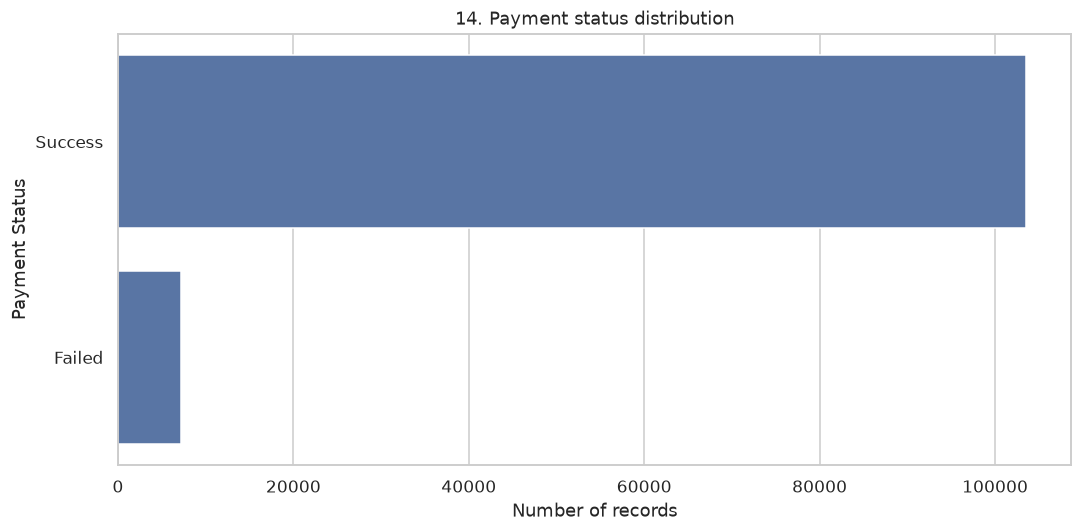

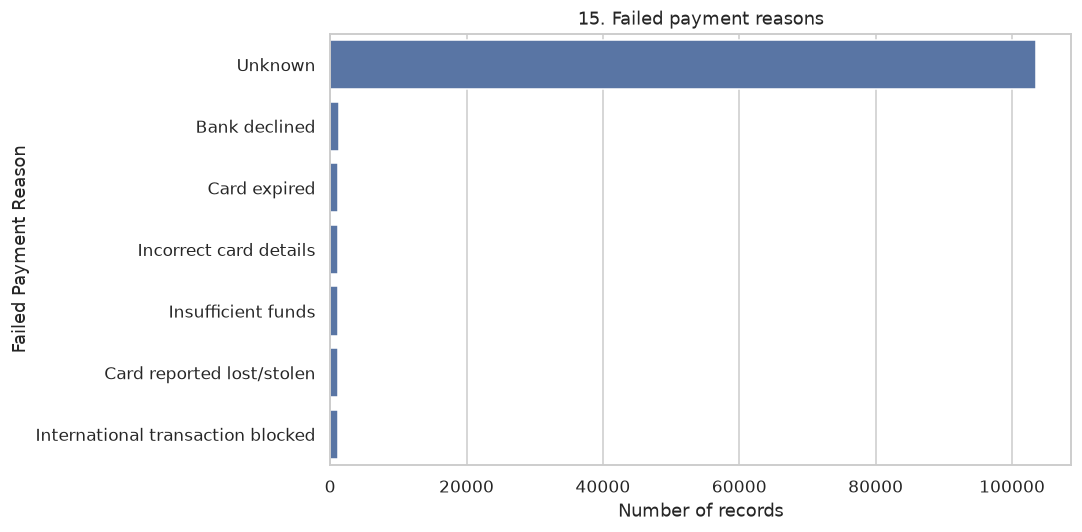

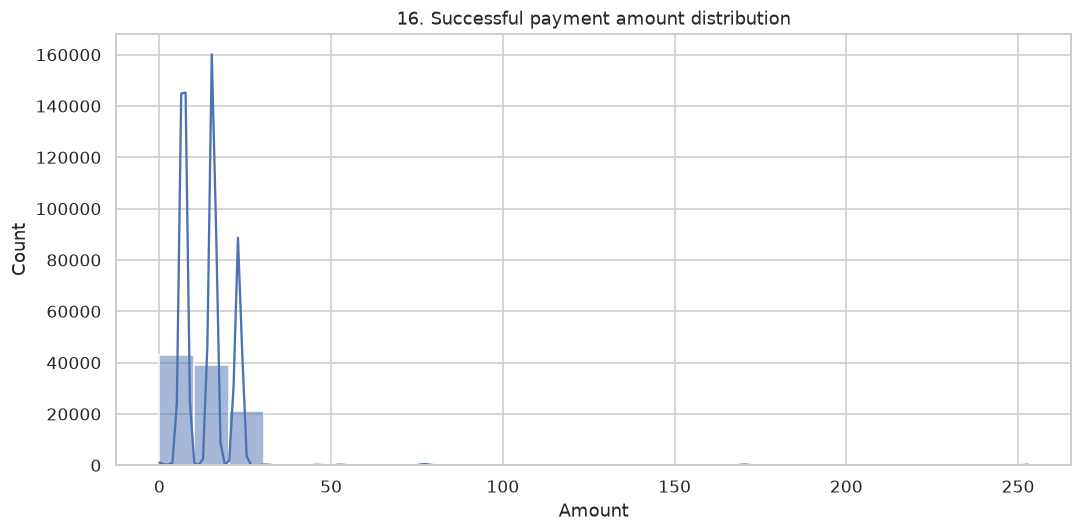

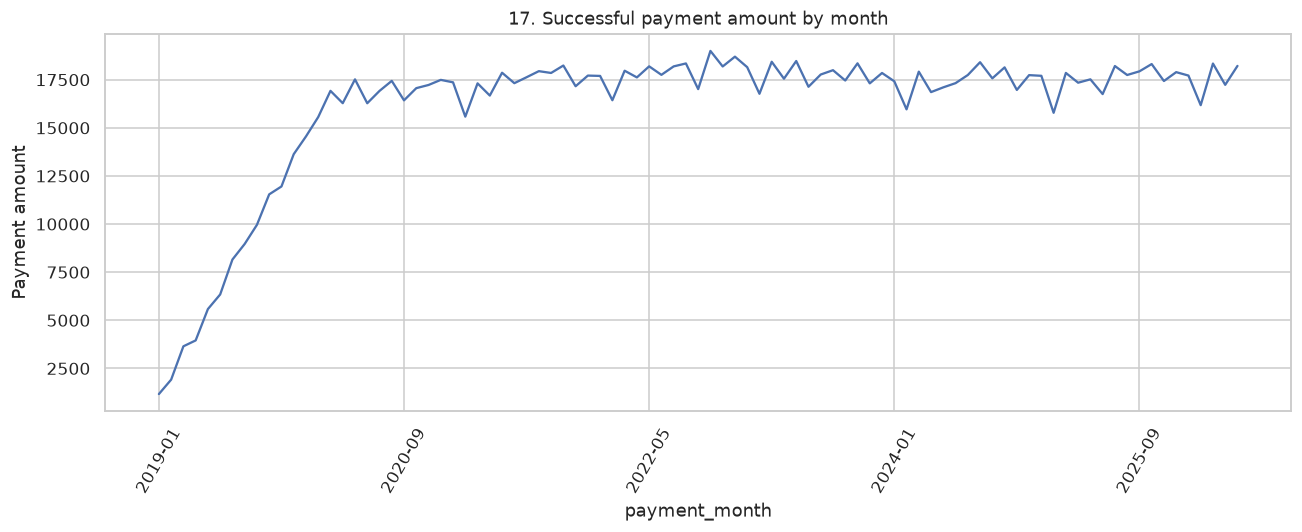

,successful_payment_amount
payment_month,
2025-06,16749.78
2025-07,18207.41
2025-08,17741.89
2025-09,17931.57
2025-10,18310.00
2025-11,17429.07
2025-12,17889.71
2026-01,17712.42
2026-02,16174.38


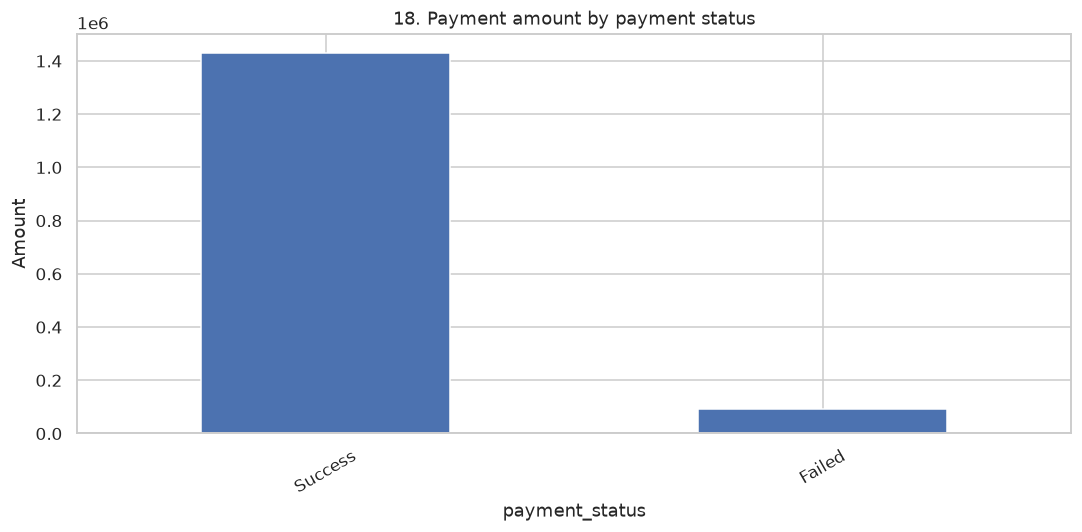

In [7]:
count_plot(successful_payments, "payment_method", "13. Successful payments by payment method")
count_plot(payments, "payment_status", "14. Payment status distribution")
count_plot(payments, "failed_payment_reason", "15. Failed payment reasons")

if "amount" in successful_payments.columns:
    hist_plot(successful_payments, "amount", "16. Successful payment amount distribution")

if {"payment_month", "amount"}.issubset(successful_payments.columns):
    revenue_trend = successful_payments.groupby("payment_month")["amount"].sum().sort_index()
    plt.figure(figsize=(12, 5))
    revenue_trend.plot()
    plt.title("17. Successful payment amount by month")
    plt.ylabel("Payment amount")
    plt.xticks(rotation=60)
    plt.tight_layout()
    plt.show()
    display(revenue_trend.tail(12).to_frame("successful_payment_amount"))

if "payment_status" in payments.columns and "amount" in payments.columns:
    payment_status_amount = payments.groupby("payment_status")["amount"].sum().sort_values(ascending=False)
    plt.figure()
    payment_status_amount.plot(kind="bar")
    plt.title("18. Payment amount by payment status")
    plt.ylabel("Amount")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()


## 8. Churn analysis

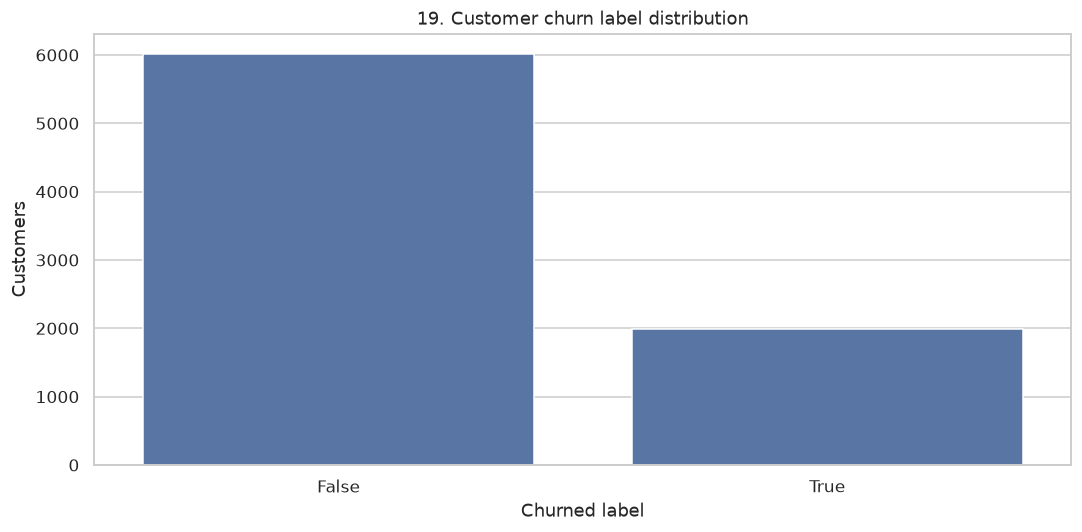

Observed churn-label rate: 24.89%


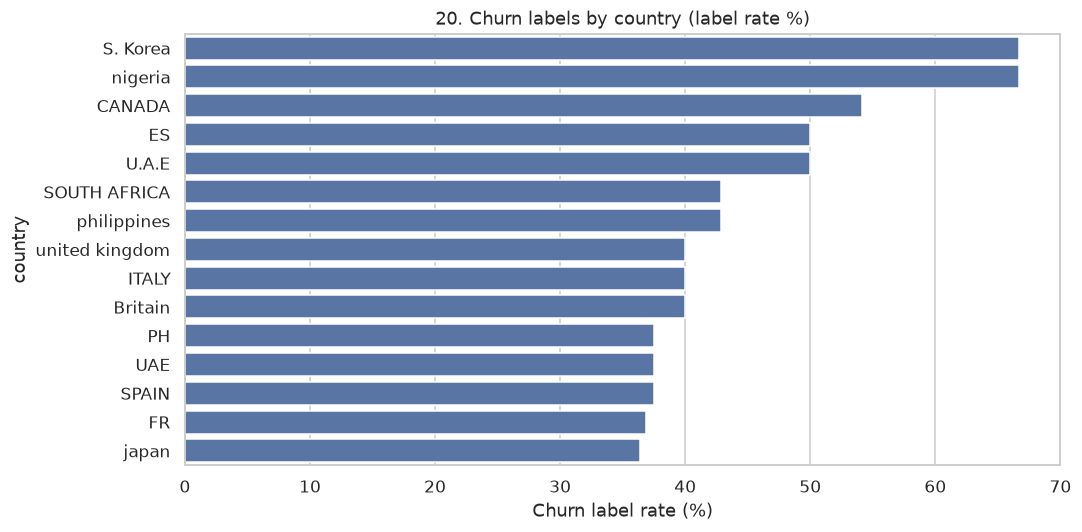

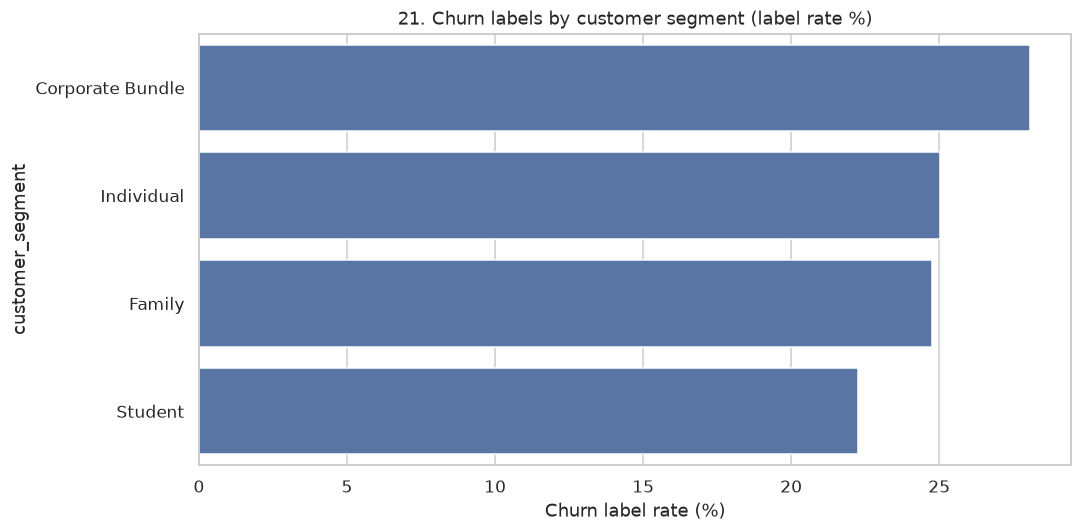

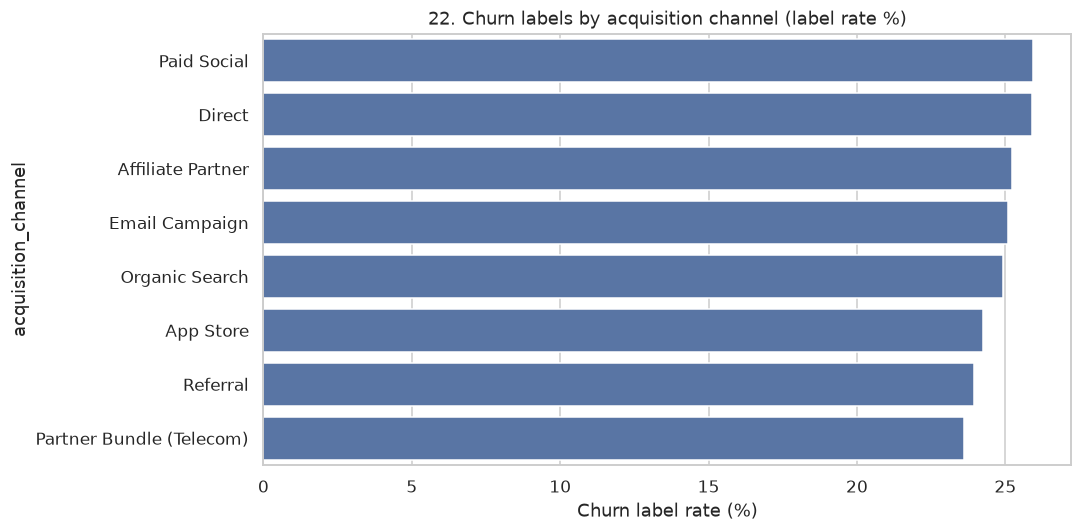

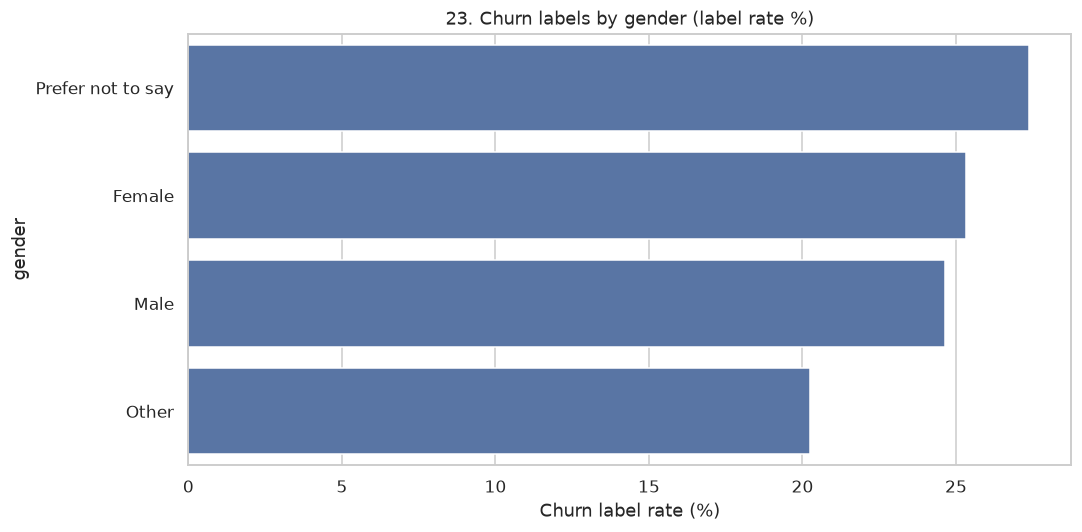

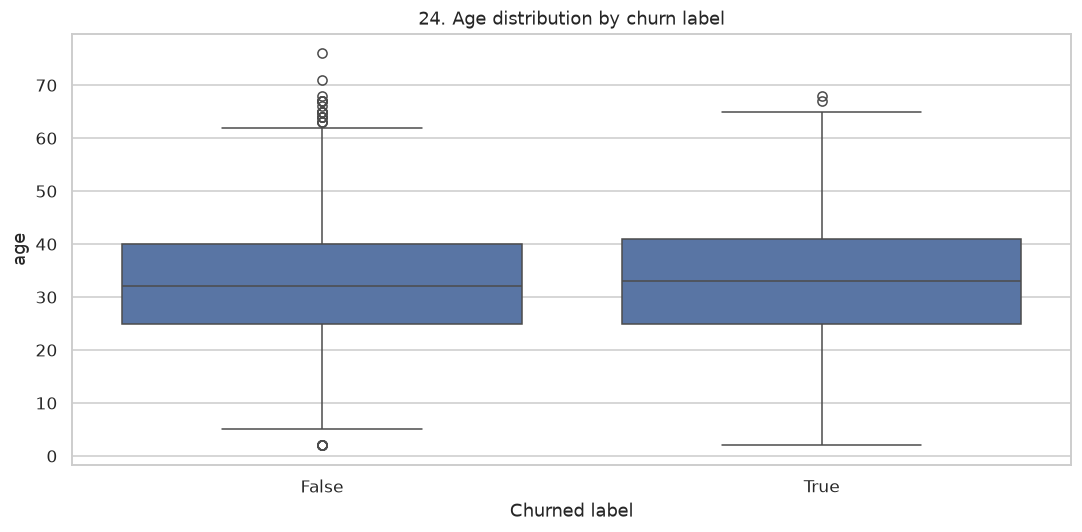

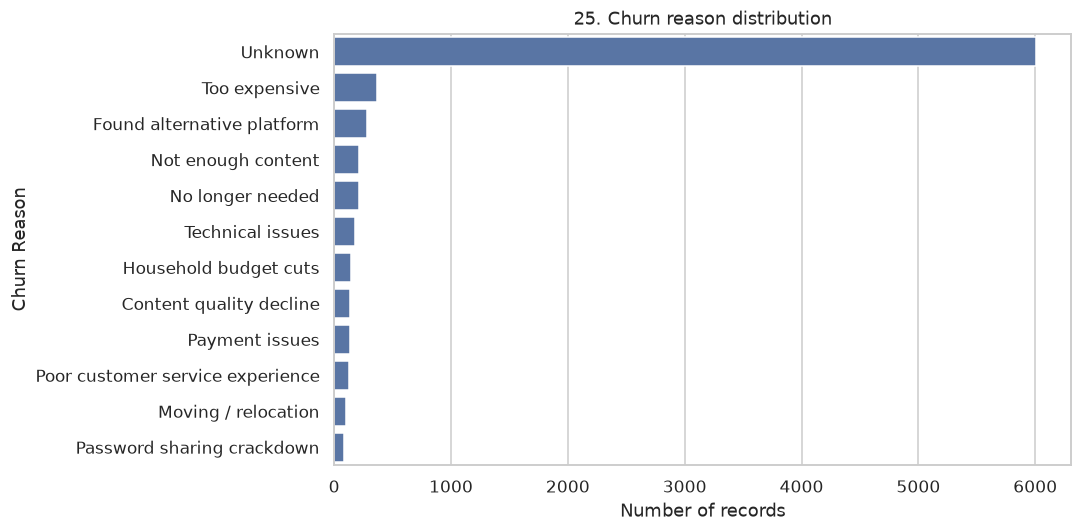

In [8]:
if "churned" in customer_churn.columns:
    churn_counts = customer_churn["churned"].value_counts(dropna=False).sort_index()
    plt.figure()
    sns.barplot(x=churn_counts.index.astype(str), y=churn_counts.values)
    plt.title("19. Customer churn label distribution")
    plt.xlabel("Churned label")
    plt.ylabel("Customers")
    plt.tight_layout()
    plt.show()

    churn_rate = pd.to_numeric(customer_churn["churned"], errors="coerce").mean() * 100
    print(f"Observed churn-label rate: {churn_rate:.2f}%")

    for col, title in [
        ("country", "20. Churn labels by country"),
        ("customer_segment", "21. Churn labels by customer segment"),
        ("acquisition_channel", "22. Churn labels by acquisition channel"),
        ("gender", "23. Churn labels by gender"),
    ]:
        if col in customer_churn.columns:
            temp = customer_churn.dropna(subset=["churned"]).copy()
            temp["churned"] = pd.to_numeric(temp["churned"], errors="coerce")
            summary = temp.groupby(col)["churned"].mean().mul(100).sort_values(ascending=False).head(15)
            plt.figure()
            sns.barplot(x=summary.values, y=summary.index.astype(str))
            plt.title(title + " (label rate %)")
            plt.xlabel("Churn label rate (%)")
            plt.tight_layout()
            plt.show()

if {"age", "churned"}.issubset(customer_churn.columns):
    temp = customer_churn.copy()
    temp["churned"] = pd.to_numeric(temp["churned"], errors="coerce")
    plt.figure()
    sns.boxplot(data=temp, x="churned", y="age")
    plt.title("24. Age distribution by churn label")
    plt.xlabel("Churned label")
    plt.tight_layout()
    plt.show()

if "churn_reason" in churn.columns:
    count_plot(churn, "churn_reason", "25. Churn reason distribution")


## 9. Viewing behaviour and content performance

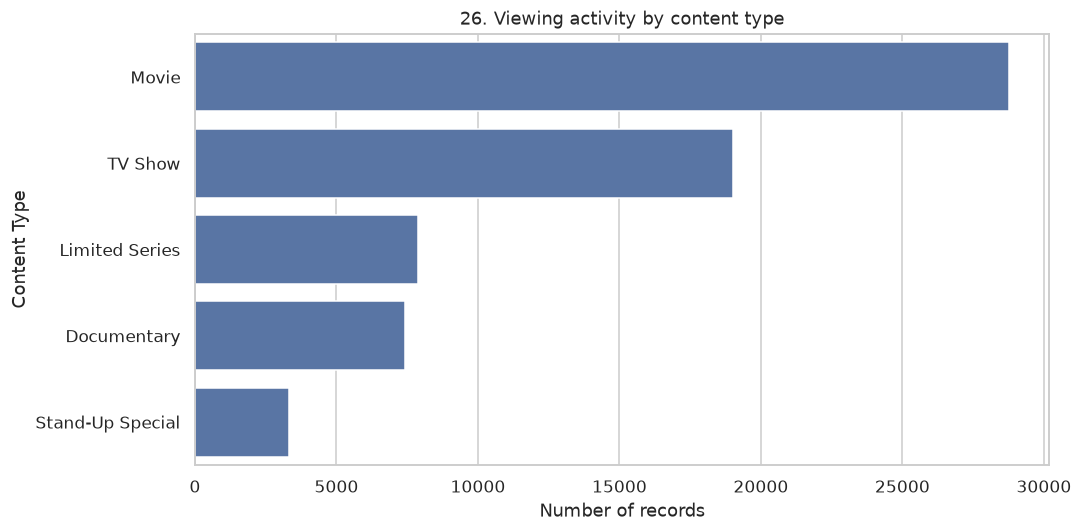

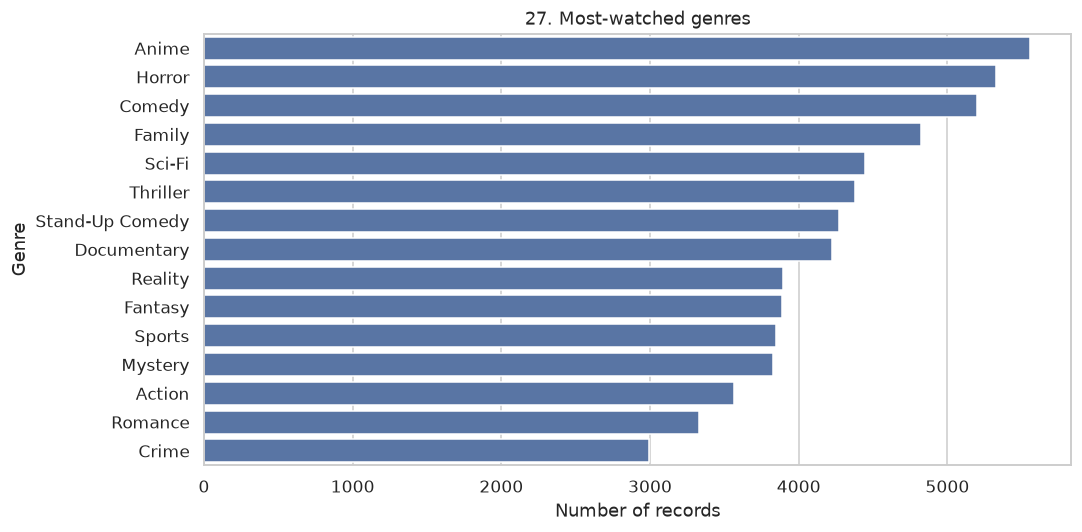

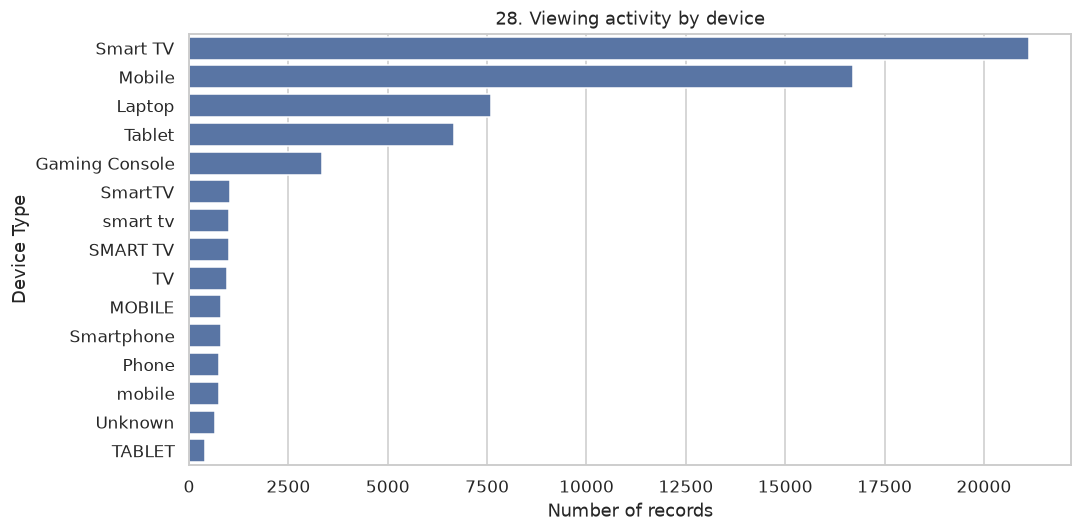

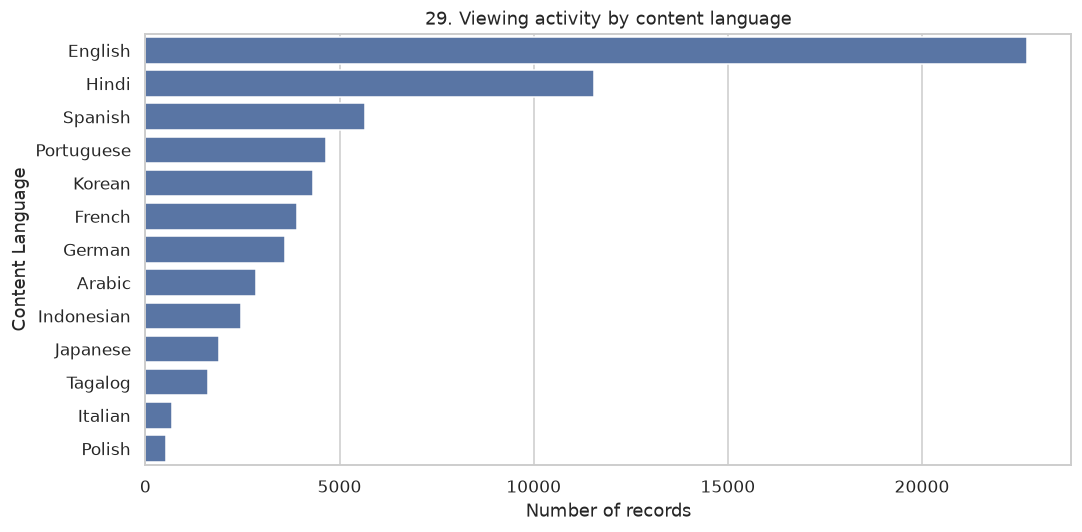

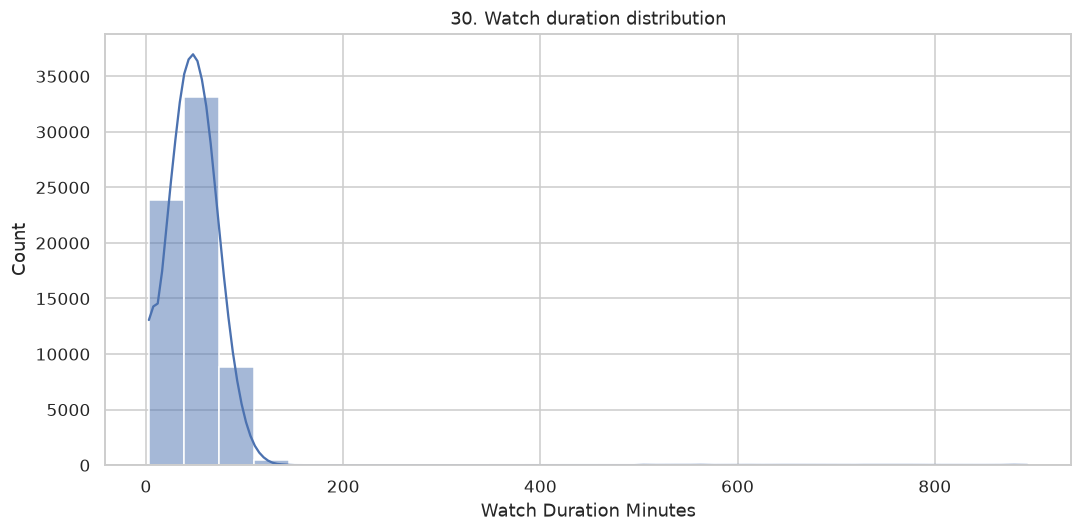

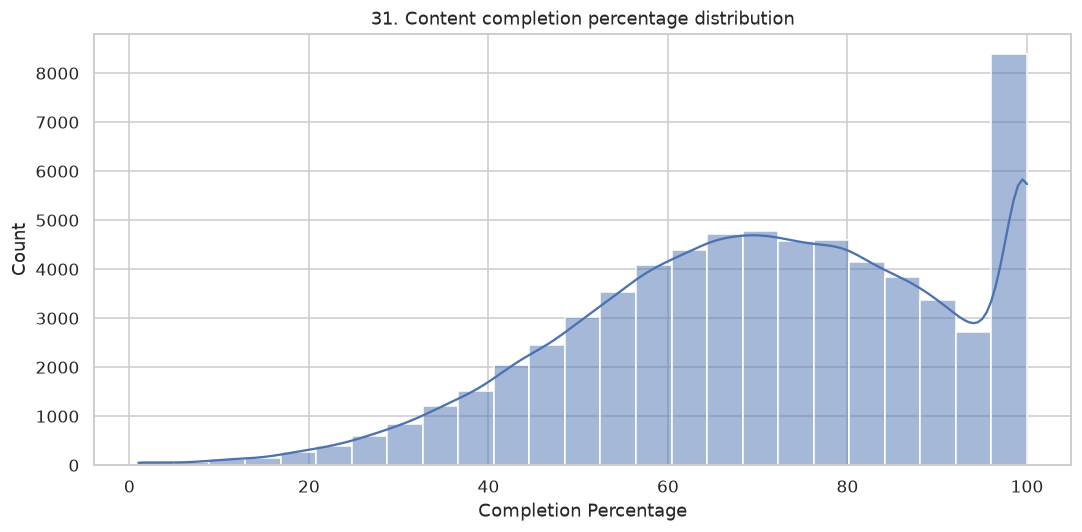

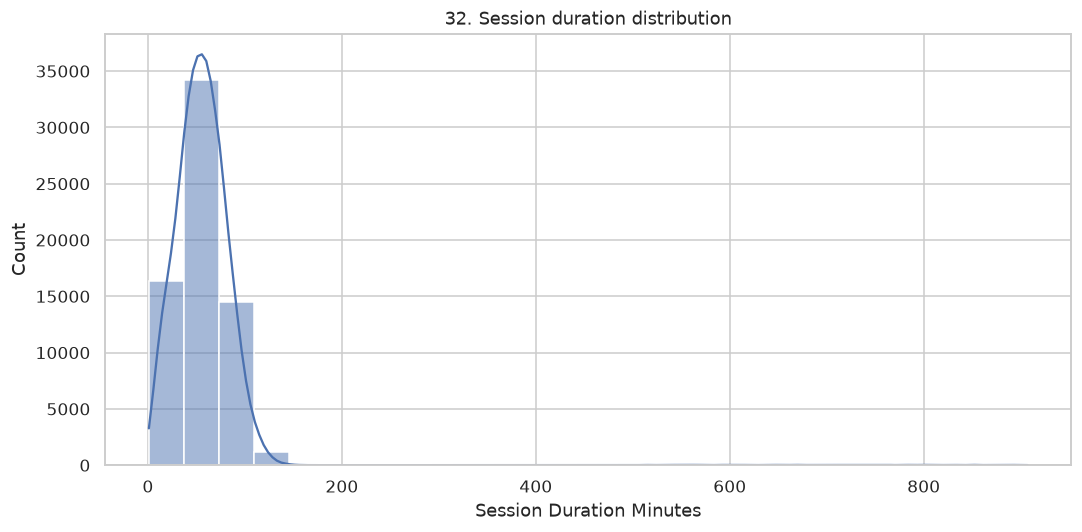

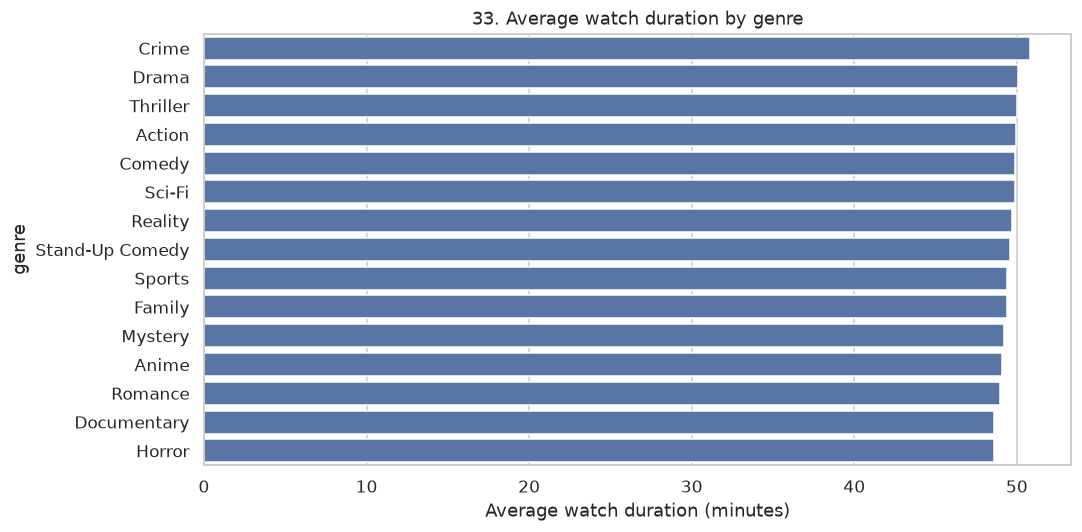

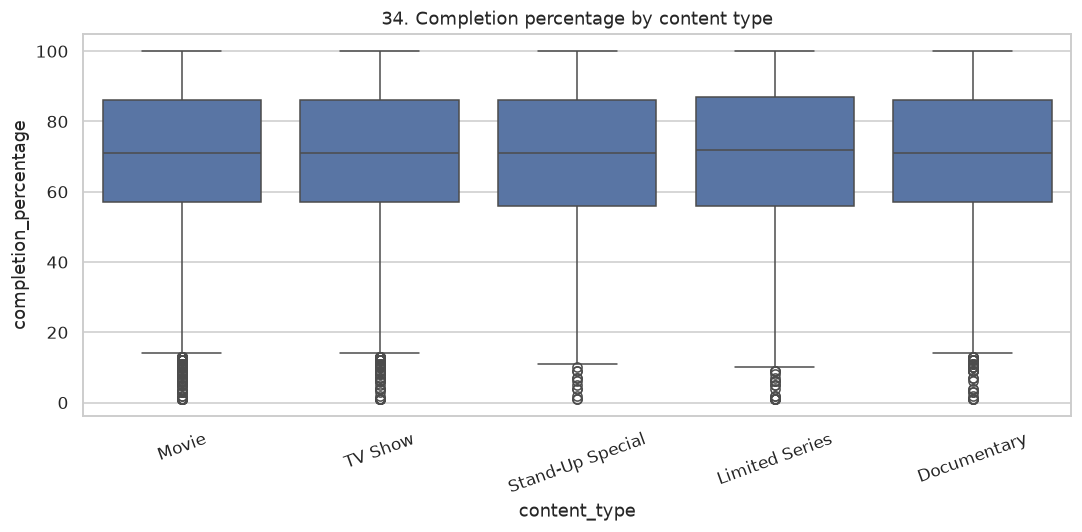

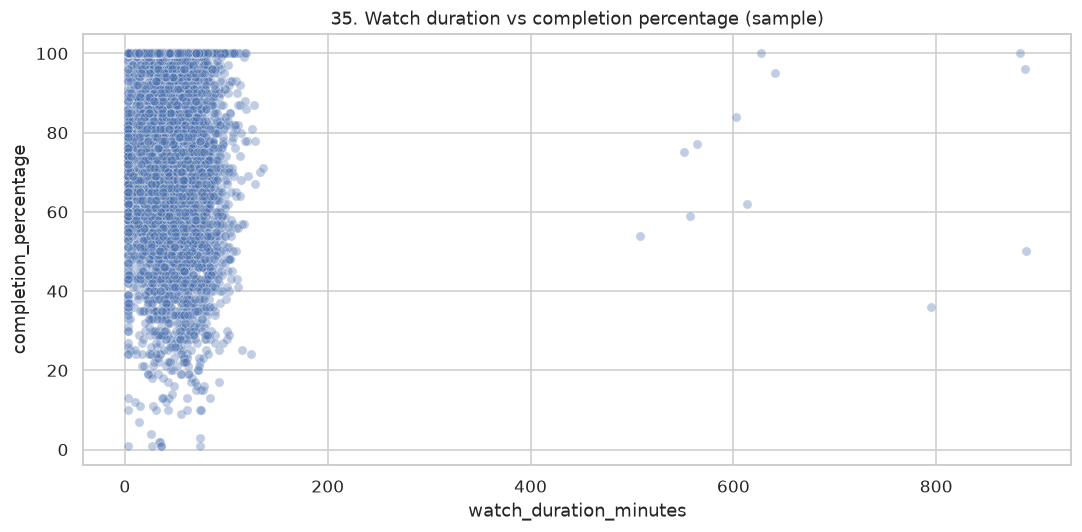

In [9]:
count_plot(viewing_content, "content_type", "26. Viewing activity by content type")
count_plot(viewing_content, "genre", "27. Most-watched genres", top=15)
count_plot(viewing_content, "device_type", "28. Viewing activity by device")
count_plot(viewing_content, "content_language", "29. Viewing activity by content language")

hist_plot(viewing, "watch_duration_minutes", "30. Watch duration distribution")
hist_plot(viewing, "completion_percentage", "31. Content completion percentage distribution")
hist_plot(viewing, "session_duration_minutes", "32. Session duration distribution")

if {"genre", "watch_duration_minutes"}.issubset(viewing_content.columns):
    genre_watch = viewing_content.groupby("genre")["watch_duration_minutes"].mean().dropna().sort_values(ascending=False).head(15)
    plt.figure()
    sns.barplot(x=genre_watch.values, y=genre_watch.index.astype(str))
    plt.title("33. Average watch duration by genre")
    plt.xlabel("Average watch duration (minutes)")
    plt.tight_layout()
    plt.show()

if {"content_type", "completion_percentage"}.issubset(viewing_content.columns):
    plt.figure()
    sns.boxplot(data=viewing_content, x="content_type", y="completion_percentage")
    plt.title("34. Completion percentage by content type")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

if {"watch_duration_minutes", "completion_percentage"}.issubset(viewing.columns):
    sample = viewing[["watch_duration_minutes", "completion_percentage"]].apply(pd.to_numeric, errors="coerce").dropna()
    if len(sample) > 5000:
        sample = sample.sample(5000, random_state=42)
    plt.figure()
    sns.scatterplot(data=sample, x="watch_duration_minutes", y="completion_percentage", alpha=0.35)
    plt.title("35. Watch duration vs completion percentage (sample)")
    plt.tight_layout()
    plt.show()


## 10. Customer support and feedback

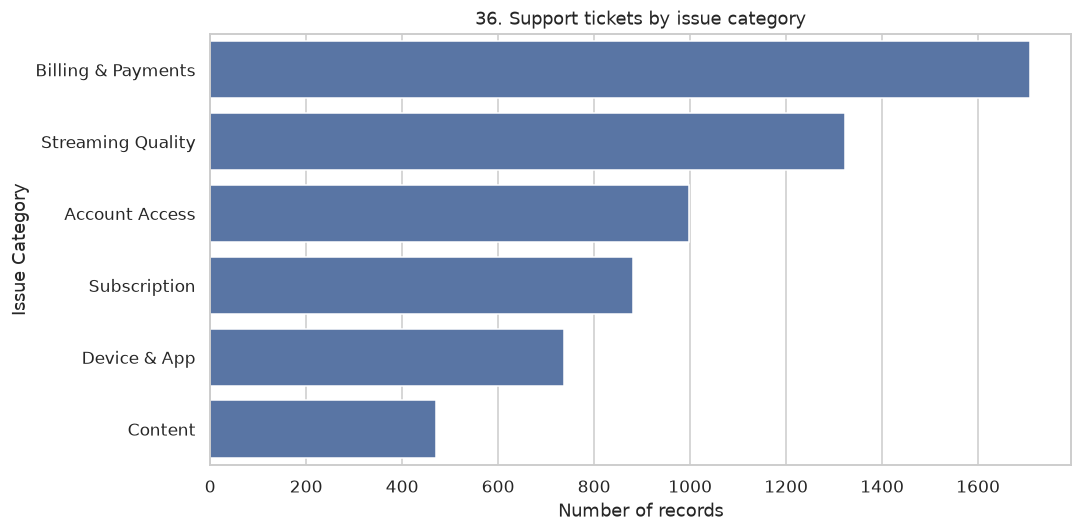

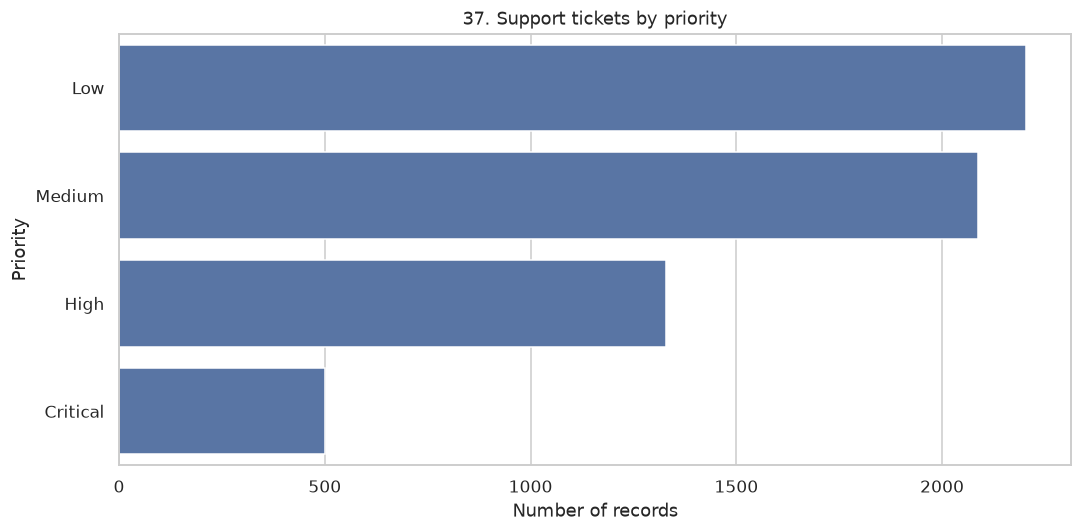

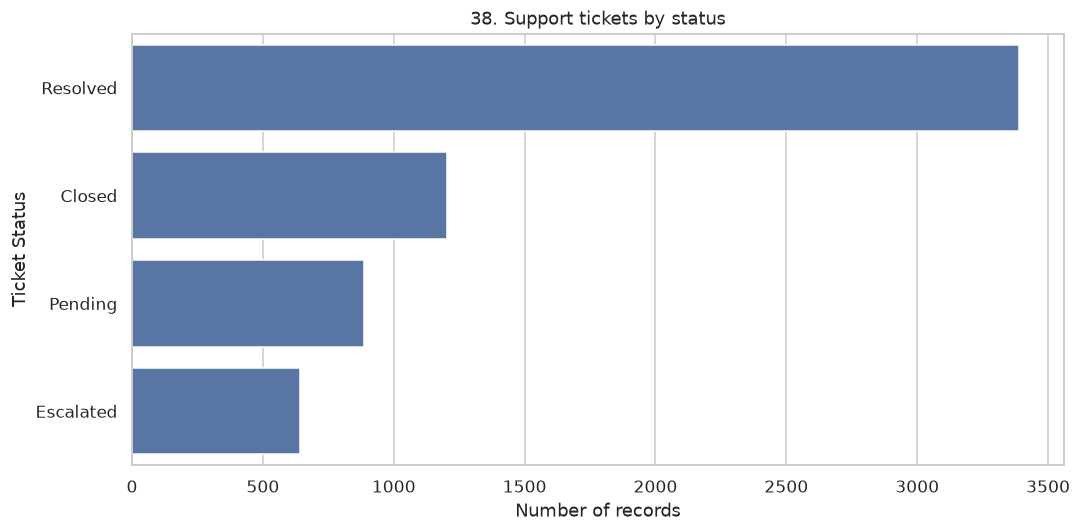

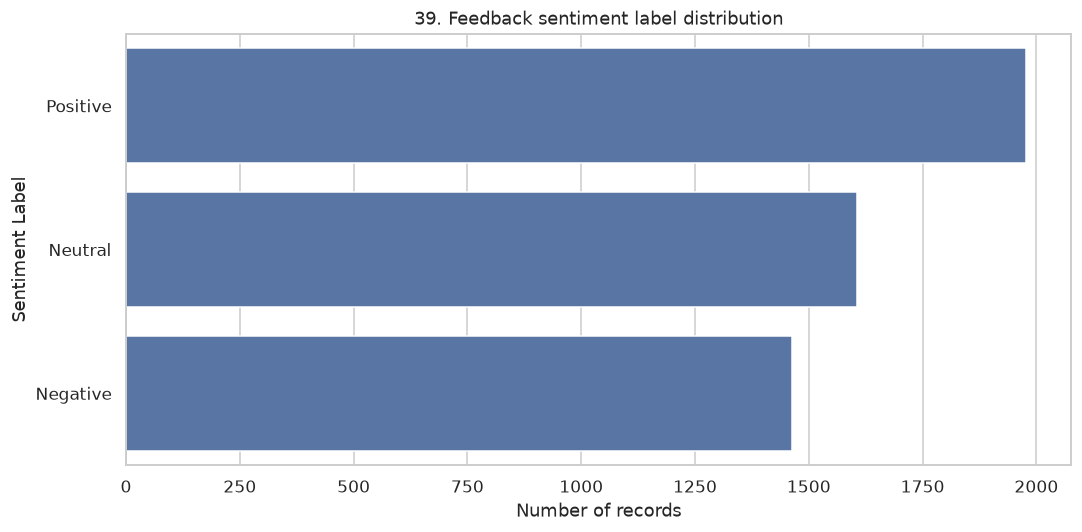

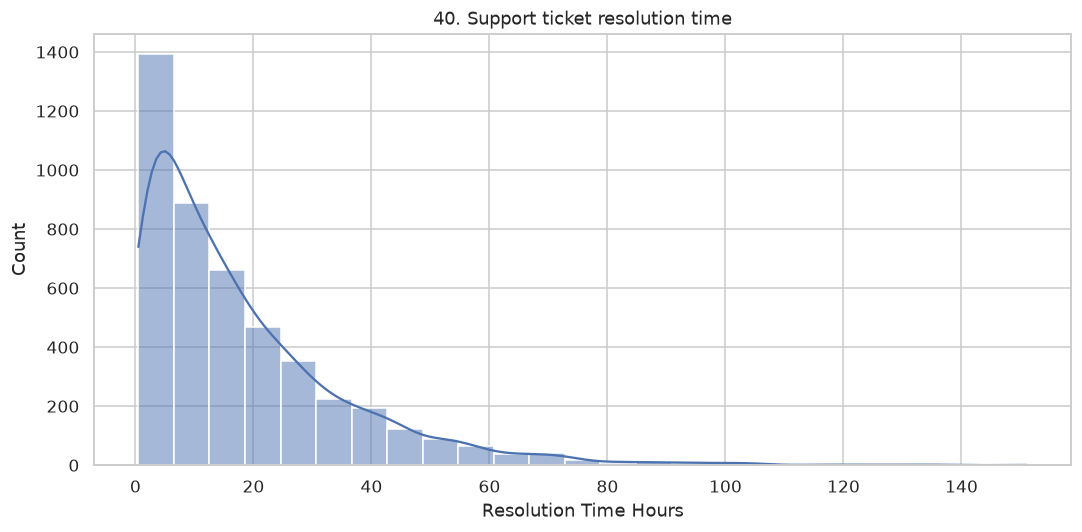

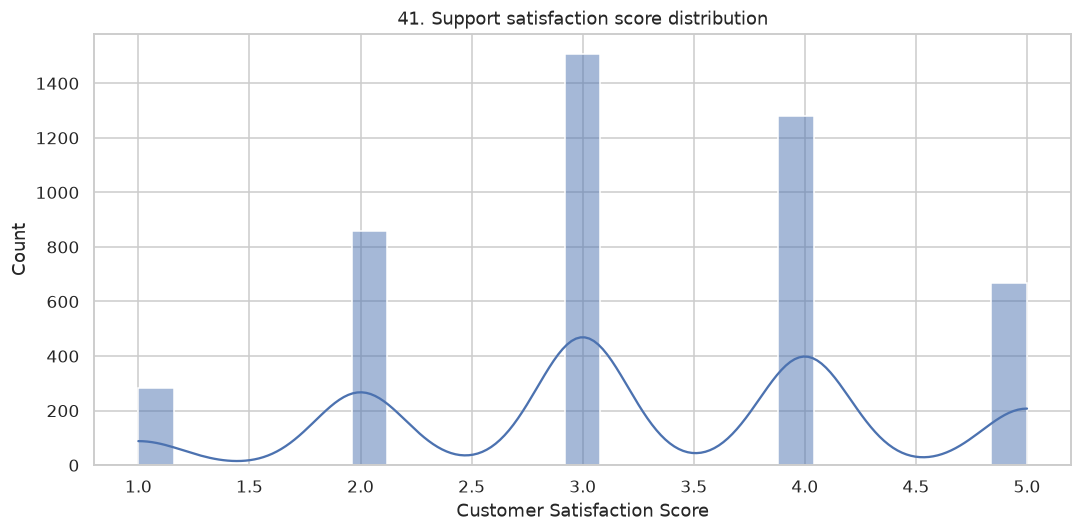

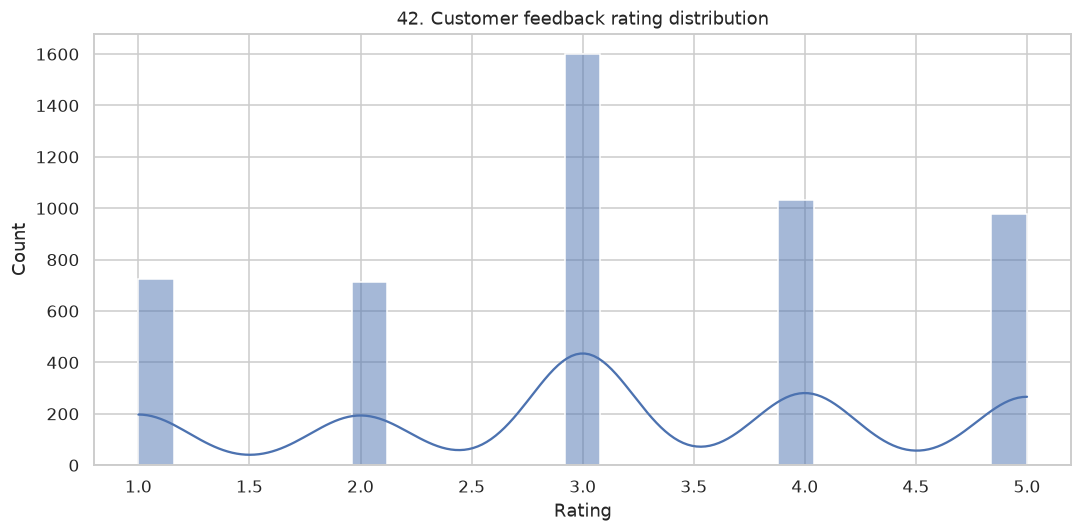

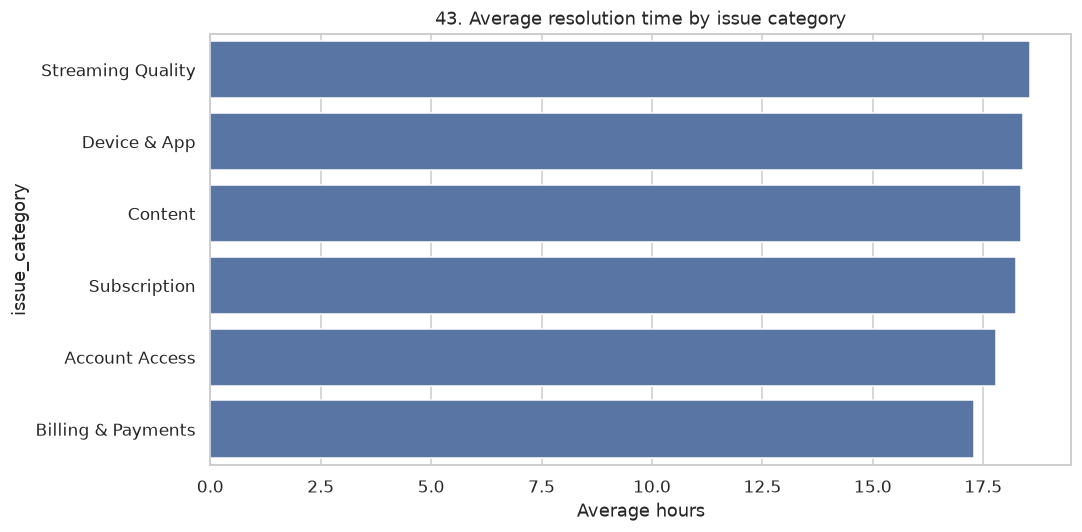

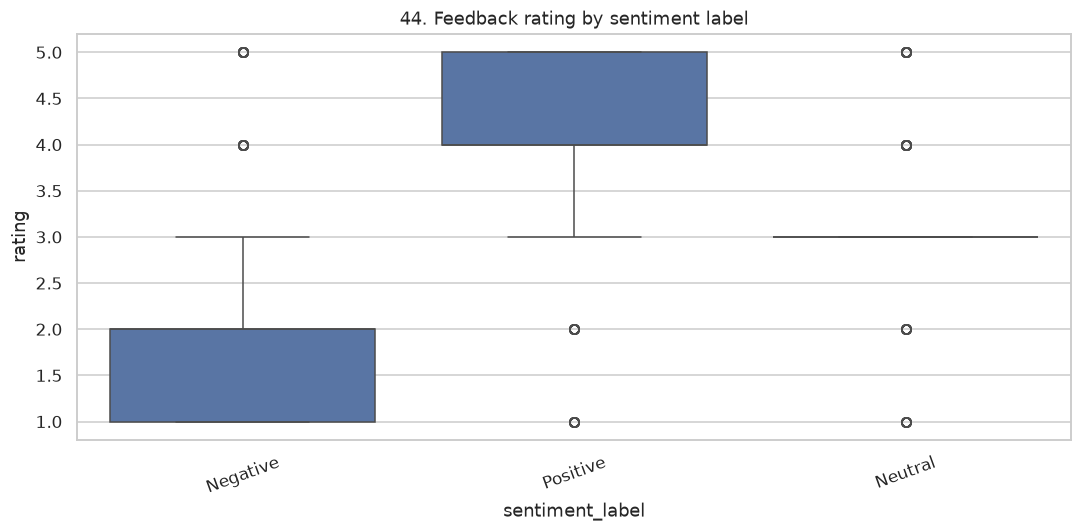

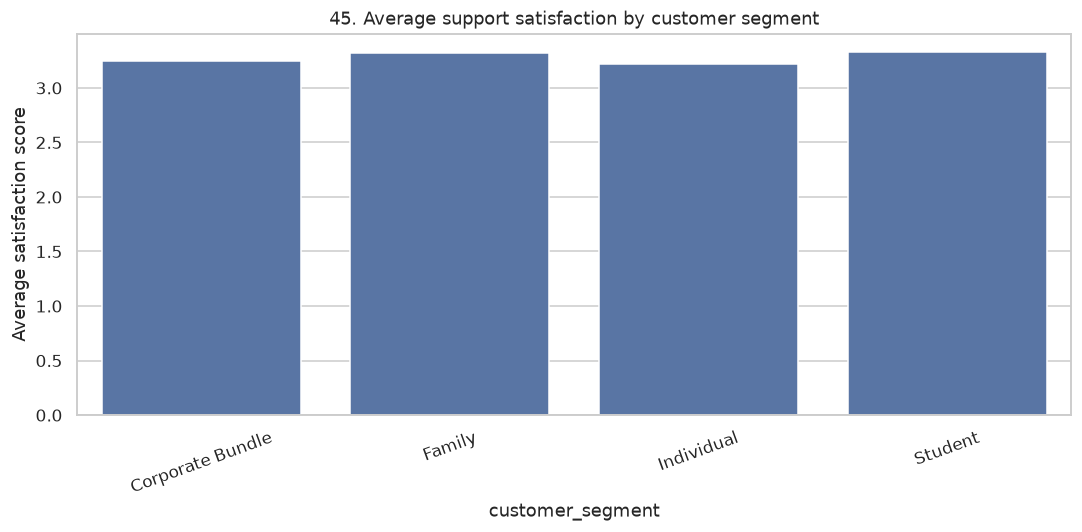

In [10]:
count_plot(tickets_customer, "issue_category", "36. Support tickets by issue category")
count_plot(tickets, "priority", "37. Support tickets by priority")
count_plot(tickets, "ticket_status", "38. Support tickets by status")
count_plot(feedback, "sentiment_label", "39. Feedback sentiment label distribution")

hist_plot(tickets, "resolution_time_hours", "40. Support ticket resolution time")
hist_plot(tickets, "customer_satisfaction_score", "41. Support satisfaction score distribution")
hist_plot(feedback, "rating", "42. Customer feedback rating distribution")

if {"issue_category", "resolution_time_hours"}.issubset(tickets.columns):
    resolution = tickets.groupby("issue_category")["resolution_time_hours"].mean().dropna().sort_values(ascending=False)
    plt.figure()
    sns.barplot(x=resolution.values, y=resolution.index.astype(str))
    plt.title("43. Average resolution time by issue category")
    plt.xlabel("Average hours")
    plt.tight_layout()
    plt.show()

if {"sentiment_label", "rating"}.issubset(feedback.columns):
    plt.figure()
    sns.boxplot(data=feedback, x="sentiment_label", y="rating")
    plt.title("44. Feedback rating by sentiment label")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

if {"customer_segment", "customer_satisfaction_score"}.issubset(tickets_customer.columns):
    satisfaction = tickets_customer.groupby("customer_segment")["customer_satisfaction_score"].mean().dropna()
    plt.figure()
    sns.barplot(x=satisfaction.index.astype(str), y=satisfaction.values)
    plt.title("45. Average support satisfaction by customer segment")
    plt.ylabel("Average satisfaction score")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()


## 11. Correlation and feature relationships

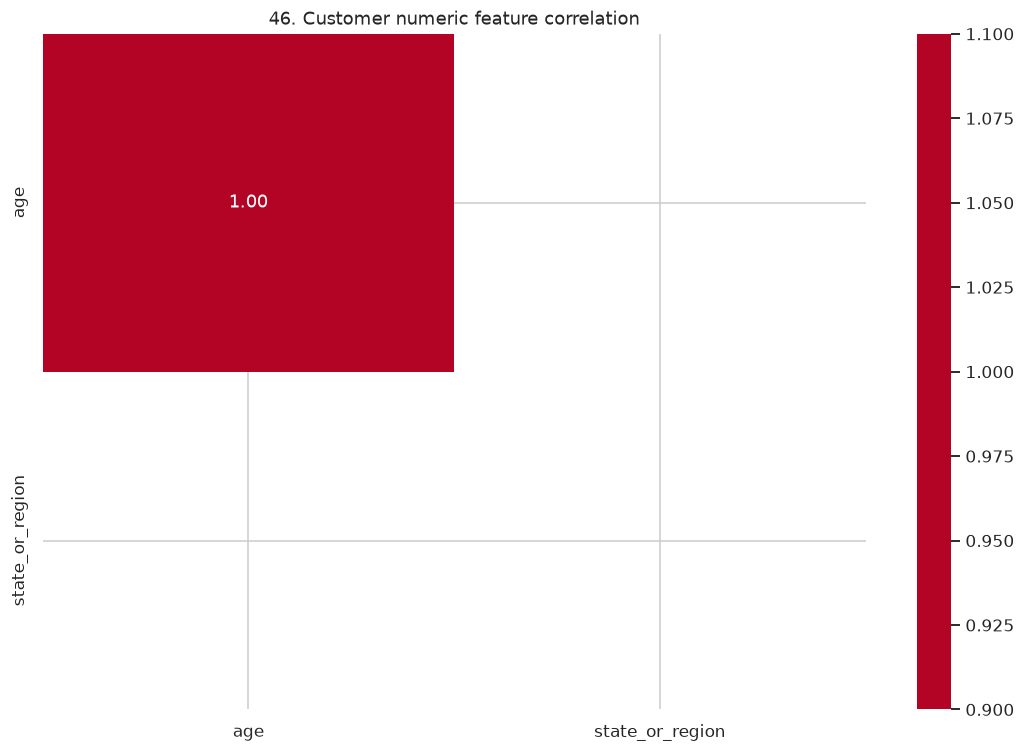

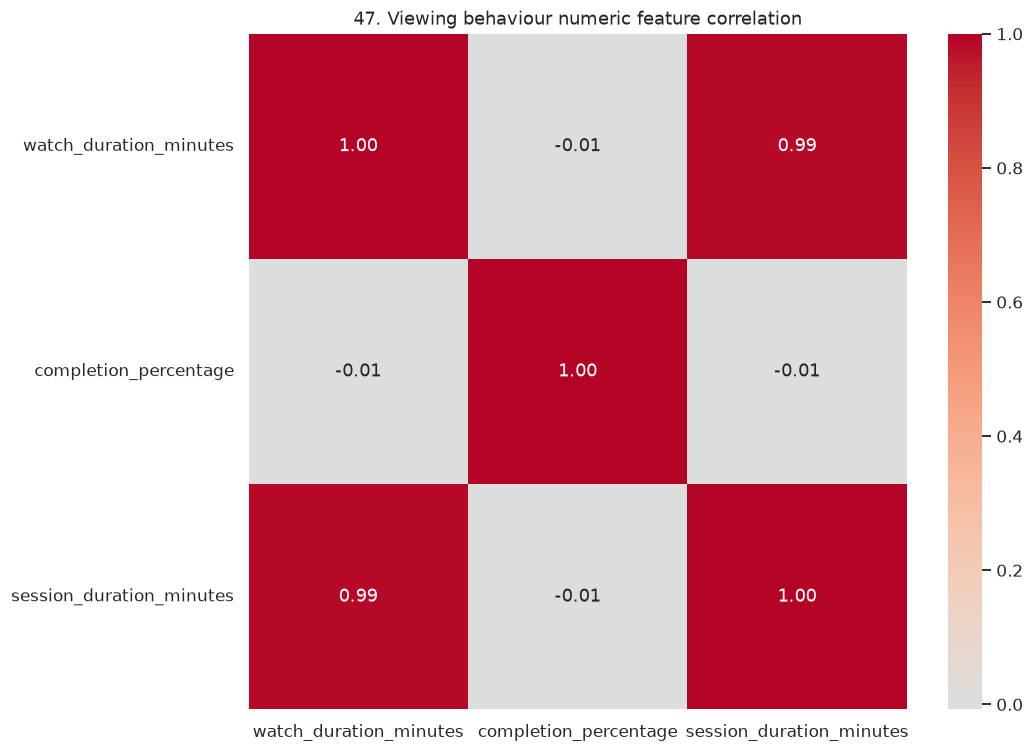

In [11]:
numeric_customers = customers.select_dtypes(include=np.number)
if numeric_customers.shape[1] >= 2:
    plt.figure(figsize=(10, 7))
    sns.heatmap(numeric_customers.corr(), annot=True, cmap="coolwarm", center=0, fmt=".2f")
    plt.title("46. Customer numeric feature correlation")
    plt.tight_layout()
    plt.show()

numeric_viewing = viewing.select_dtypes(include=np.number)
if numeric_viewing.shape[1] >= 2:
    plt.figure(figsize=(10, 7))
    sns.heatmap(numeric_viewing.corr(), annot=True, cmap="coolwarm", center=0, fmt=".2f")
    plt.title("47. Viewing behaviour numeric feature correlation")
    plt.tight_layout()
    plt.show()


## 12. Business findings and automated summary

In [12]:
summary = {
    "customers": len(customers),
    "subscription_records": len(subscriptions),
    "payment_records": len(payments),
    "successful_payment_records": len(successful_payments),
    "viewing_records": len(viewing),
    "support_tickets": len(tickets),
    "feedback_records": len(feedback),
    "content_items": len(content),
}

if "churned" in customer_churn.columns:
    summary["customers_with_churn_label"] = int(customer_churn["churned"].notna().sum())
    summary["observed_churn_rate_pct"] = round(
        pd.to_numeric(customer_churn["churned"], errors="coerce").mean() * 100, 2
    )

if "amount" in successful_payments.columns:
    summary["successful_payment_amount_total"] = round(
        pd.to_numeric(successful_payments["amount"], errors="coerce").sum(), 2
    )

display(pd.DataFrame(summary.items(), columns=["Metric", "Value"]))
pd.DataFrame(summary.items(), columns=["Metric", "Value"]).to_csv(
    REPORTS / "eda_business_summary.csv", index=False
)

print("EDA summary saved to:", REPORTS.resolve())


,Metric,Value
0,customers,8000.00
1,subscription_records,8875.00
2,payment_records,110735.00
3,successful_payment_records,103529.00
4,viewing_records,66422.00
5,support_tickets,6120.00
6,feedback_records,5046.00
7,content_items,500.00
8,customers_with_churn_label,8000.00
9,observed_churn_rate_pct,24.89


EDA summary saved to: /workspaces/Netflix-Customer-Intelligence/data/reports/eda


## 13. Business interpretation and recommendations

Use the charts and observed data to assess:

1. **Churn prevention:** Identify customer segments and acquisition channels with higher observed churn-label rates. These are associations, not causal explanations.
2. **Revenue protection:** Monitor successful payment trends separately from failed payments and subscription-record counts.
3. **Engagement:** Investigate genres, devices and content types associated with stronger watch duration and completion.
4. **Customer experience:** Prioritize support issue categories with longer resolution times and weaker satisfaction scores.
5. **Feedback quality:** Sentiment labels may contain noise. Compare sentiment with ratings and feedback text before making decisions.
6. **Data quality:** Review missing values, duplicate records and join coverage before interpreting any metric.

### Important analytical limitations

- Subscription records are historical records; customers can have multiple records after plan changes.
- Payment `subscription_id` values may be missing. Do not assume direct payment-to-subscription joins are complete.
- Successful payment totals are transaction-based and are not automatically equivalent to recognized accounting revenue or monthly recurring revenue.
- Churn labels represent the supplied labelled dataset, not necessarily a real-time churn prediction.
- Correlation and group-level differences do not prove causation.
- Missing or undated support and feedback records can limit time-based conclusions.
